# 136 · How does decres-rescale-aug10-v1 work, and why does it fail where it fails?

Run `decres-rescale-aug10-v1` (src9 transformer4, res decoder, rescaled latent, augs on 10% of samples, ep300). Eval is **eager fp32** (compile eval bug).
100 lasers (10×10 grid on the box wall) × 1170 bins (100–1000 Hz, 2 axes) → per-sample z-score → 18 bands × 65 bins tokens → freq transformer per laser → laser transformer → 512-d latent `u` → conv decoder → 64×64 mask.

Ten questions a CVPR reviewer would ask, each with a measurement, a figure and an answer:

1. **Which parts of the signal does the model read?** Bands, axes, fine spectral structure, spatial pattern across lasers.
2. **Is there a physical object signature (mass loading), and does detectability follow it?** Cylinder mass series, Δ spectrum vs the empty box.
3. **Where is position information in the raw input, and how much does the network add?** Linear probes on raw / empty-subtracted / latent features.
4. **What is the geometry of the latent?** Which factors live in `u`, its effective dimension, and how many dims the decoder actually uses.
5. **Interpolation or lookup?** Model vs nearest-neighbour oracles, IoU vs distance to the nearest training position.
6. **What predicts per-sample success?** A grouped-CV model of per-sample IoU from data/model properties.
7. **Does the model know when it fails?** Confidence, latent-novelty and input-novelty as failure detectors; threshold behaviour.
8. **How invariant is it to the speaker (excitation) and to noise?** Latent variance decomposition, test-time speaker-response and SNR sweeps.
9. **How does the laser array encode space?** Per-laser importance, redundancy, grid shift / mirror tests, why shifted-laser splits break.
10. **What happens off-distribution?** Lid, unseen objects, shifted lasers: latent novelty vs IoU, which known class the model snaps to.

Heavy passes (all 15.9k samples; ~200 perturbations on a 2.1k stratified subset) were computed once by the cache cell below → `runs/_src9_cache/nb136/`.

In [1]:
import sys, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats, ndimage
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src9"))
from dataset import load_splits, CATEGORIES, NOT_OOD
CACHE = ROOT / "runs/_src9_cache/nb136"
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
B, A, INFO = np.load(CACHE / "base.npz"), np.load(CACHE / "ablate.npz"), torch.load(CACHE / "info.pt", weights_only=False)
samples, _ = load_splits(); metas = list(samples.values())
HZ = 100 + (np.arange(18) * 65 + 32) * 900 / 1169                     # band centres, Hz (50 Hz bands)
FHZ = np.linspace(100, 1000, 1170)

2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

### Cache (run once)
The two passes are standalone scripts kept short; they are reproduced here for the record and only run if the cache is missing.
`base`: every sample → `u`, mask, logits, laser-mean log spectrum `spec` (N,1170,2), per-laser per-band log level `lb` (N,100,18).
`ablate`: stratified eval subset (≤30 object samples / split, 300 train) × perturbations (band / laser / row / column drop, random drops, speaker-response, SNR, grid jitter, mirror, spectral shuffle / smoothing, latent PC truncation) → IoU@.08, area, CoM.

In [2]:
if not (CACHE / "ablate.npz").exists():   # ~1 min + ~8 min on one GPU
    import subprocess
    for f in ("scripts/nb136_base.py", "scripts/nb136_ablate.py"): subprocess.run([sys.executable, f], check=True, cwd=ROOT)

### Per-sample table

In [3]:
BOX = {"2026_09_27_gastronorm_four_objs": "gastro", "2026_10_05_green_plastic_four_objs": "plastic", "2026_10_11_cardboard_four_objs": "cardboard"}
CAT = {(b, s): c for b, cs in CATEGORIES.items() for c, ss in cs.items() for s in ss}
N = len(B["i"]); P = B["p"].astype(np.float32) / 255; Y = B["y"]; Pb = P > 0.08
rr, cc = np.mgrid[:64, :64]
def com(m): a = m.sum((1, 2)).clip(1e-6); return np.stack([(m * rr).sum((1, 2)) / a, (m * cc).sum((1, 2)) / a], 1)
M = [metas[i] for i in B["i"]]
df = pd.DataFrame(dict(split=B["split"], box=[BOX[m["experiment"]] for m in M], obj=["+".join(sorted(m["objects"])) for m in M],
                       n_obj=[m["n_objects"] for m in M], pos=[m["position_id"] for m in M], spk=[m["speaker"] for m in M], exp=[m["experiment"] for m in M]))
df["name"] = [s.split("/")[-1] for s in df.split]
df["cat"] = [("train" if s == "train" else CAT.get((b, n), "?")) for s, b, n in zip(df.split, df.box, df.name)]
df["ood"] = ~df.cat.isin(NOT_OOD + ("train",))
df["area"], df["parea"] = Y.sum((1, 2)), Pb.sum((1, 2))
df["iou"] = (Pb & Y).sum((1, 2)) / np.maximum((Pb | Y).sum((1, 2)), 1)
df[["r", "c"]], df[["pr", "pc"]] = com(Y.astype(float)), com(Pb.astype(float))
df["edge"] = np.minimum.reduce([df.r, df.c, 63 - df.r, 63 - df.c])            # true CoM distance to the box wall, px
df["conf"] = np.where(df.parea > 0, (P * Pb).sum((1, 2)) / np.maximum(df.parea, 1), 0)   # mean prob inside the predicted mask
U = B["u"].astype(np.float32); TR = (df.split == "train").values; EV = ~TR & (df.area > 0).values
print(df[EV].groupby("cat").iou.agg(["mean", "count"]).round(3).T.to_string()); print("train iou", df[TR & (df.area > 0)].iou.mean().round(3))

cat    broken  control  cylinder        id     lid  multiple  rotated  unseen-angle  unseen-laser  unseen-object  unseen-position  unseen-rotated-object  unseen-speaker
mean     0.41    0.652     0.126     0.754   0.076     0.383    0.552         0.497         0.236          0.575            0.686                  0.383           0.432
count   12.00  399.000   331.000  2191.000  83.000   310.000  166.000       108.000       192.000        550.000          197.000                 36.000          85.000
train iou 0.89


## Q1 · Which parts of the signal does the model read?
Occlusion through the model's own token masks (the readout zeroes the dropped token, so no out-of-distribution fill value): one band at a time (18 × 50 Hz), whole laser rows / columns, one sensor axis (x or y duplicated), plus three structural probes: **shuffle bins** (destroys spectral order but keeps the per-laser level distribution), **smooth spectrum** (33-bin ≈ 25 Hz moving average: removes sharp resonances, keeps the envelope), **laser mean** (every laser gets the wall-average spectrum: removes all spatial information).

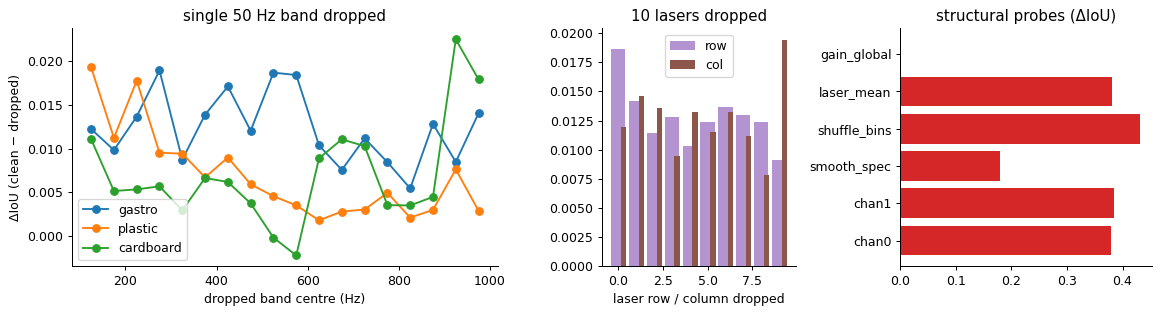

clean eval 0.455 {'chan0': np.float32(0.379), 'chan1': np.float32(0.385), 'smooth_spec': np.float32(0.179), 'shuffle_bins': np.float32(0.431), 'laser_mean': np.float32(0.382), 'gain_global': np.float32(0.0)}
top bands [(np.float32(0.014), 925), (np.float32(0.014), 124), (np.float32(0.012), 975), (np.float32(0.012), 224), (np.float32(0.01), 424)]


In [4]:
names = list(A["names"]); I = dict(zip(names, A["iou"])); sel = A["sel"]; sub = df.iloc[sel].reset_index(drop=True)
ev = (sub.split != "train").values
d = lambda k, m=ev: I["clean"][m].mean() - I[k][m].mean()
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[2.2, 1, 1.3]))
for b, col in zip(("gastro", "plastic", "cardboard"), ("C0", "C1", "C2")):
    m = ev & (sub.box == b).values
    ax[0].plot(HZ, [d(f"band{k}", m) for k in range(18)], "o-", c=col, label=b)
ax[0].set(xlabel="dropped band centre (Hz)", ylabel="ΔIoU (clean − dropped)", title="single 50 Hz band dropped"); ax[0].legend()
ax[1].bar(range(10), [d(f"lrow{k}") for k in range(10)], color="C4", alpha=.7, label="row"); ax[1].bar(np.arange(10) + .3, [d(f"lcol{k}") for k in range(10)], width=.3, color="C5", label="col")
ax[1].set(xlabel="laser row / column dropped", title="10 lasers dropped"); ax[1].legend()
ks = ["chan0", "chan1", "smooth_spec", "shuffle_bins", "laser_mean", "gain_global"]
ax[2].barh(ks, [d(k) for k in ks], color="C3"); ax[2].set(title="structural probes (ΔIoU)"); ax[2].axvline(0, c="k", lw=.5)
plt.tight_layout(); plt.show()
print("clean eval", I["clean"][ev].mean().round(3), {k: round(d(k), 3) for k in ks})
print("top bands", sorted([(round(d(f'band{k}'), 3), int(HZ[k])) for k in range(18)])[::-1][:5])

**Answer.** Dropping any single 50 Hz band costs at most .02 IoU (eval subset clean .455). No band is essential, and each box uses a different part of the spectrum: plastic leans on < 250 Hz, gastro on 250–600 Hz, cardboard on > 850 Hz. That fits boxes with different stiffness and size putting their mode-dense regions in different places. The *structure* of the signal matters much more than any band:
- **Shuffling bins** kills the model (−.43).
- **Smoothing the spectrum to ~25 Hz** costs −.18, so the sharp resonance peaks (modal lines) carry ~40% of performance and the envelope the rest.
- **Replacing every laser with the wall average** costs −.38. The *spatial pattern* across the 100 lasers is the signal; the average spectrum alone localizes nothing.
- **Duplicating one in-plane axis** costs −.38: the x/y motion ratio, i.e. the polarization of the wall's motion, is used.
- **Global gain** has no effect (per-sample z-score), as expected.
- **Rows and columns:** the grid edges (row 0, column 9) matter most (.019 vs ~.012).

## Q2 · Is there a physical object signature, and does detectability follow it?
An object on the floor adds mass and a local constraint to the plate-like floor: by Rayleigh's quotient, a point mass m at x lowers mode n by Δf_n/f_n ≈ −½·m·φ_n(x)²/M_n, proportional to the squared mode shape at the object, so position is encoded in *which* modes shift and by how much, and the shifts change the *spatial* pattern of the wall response (mode shapes re-mix), not only its average level. Tests: (a) the empty-subtracted wall-average log spectrum Δ(f) = spec − mean_empty(box, speaker); (b) the per-laser spatial pattern (band level minus its wall mean) vs empty; (c) the cylinder series 100 → 1000 g. Caveat: the cylinders are not one footprint (≈4 → 24 px at 64×64), so mass and size are confounded; cardboard cylinders are trained, gastro / plastic cylinders are fully held out.

/tmp/ipykernel_2316792/1584045261.py:9: RuntimeWarning: Mean of empty slice
  df["dmag"] = np.sqrt(np.nanmean(DSP ** 2, 1))                                   # rms Δ of the wall-average spectrum


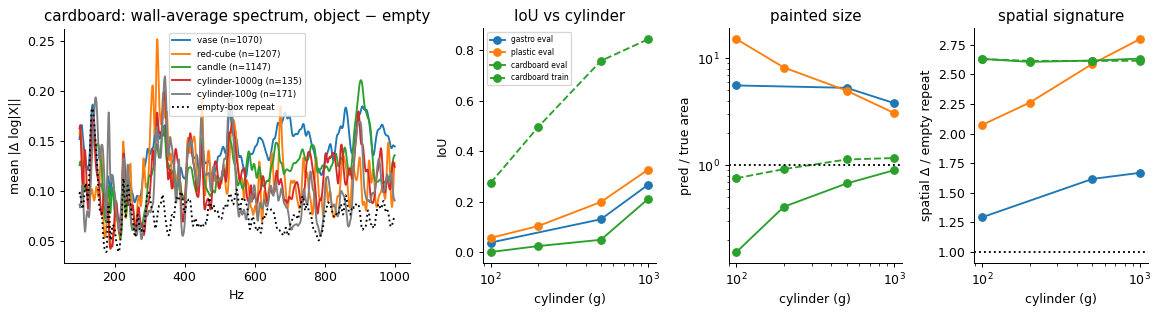

          box    set     g   iou   cerr  bound   area  parea  empty   dsp    n
0   cardboard   eval   100  0.00  46.30   0.12   4.33   0.67   0.75  0.24   36
1   cardboard   eval   200  0.02  26.22   0.27   7.90   3.22   0.45  0.24   40
2   cardboard   eval   500  0.05   7.08   0.57  14.40   9.70   0.12  0.24   40
3   cardboard   eval  1000  0.21   4.82   0.69  25.29  22.68   0.04  0.24   28
4   cardboard  train   100  0.27  20.70   0.33   4.87   3.67   0.51  0.24  135
5   cardboard  train   200  0.50   0.31   0.54   8.13   7.47   0.24  0.24  153
6   cardboard  train   500  0.76   0.17   0.78  16.06  18.14   0.05  0.24  159
7   cardboard  train  1000  0.84   0.13   0.86  24.17  28.18   0.00  0.24  107
8      gastro   eval   100  0.04  21.63   0.09   3.50  19.50   0.33  0.06    6
9      gastro   eval   500  0.13   3.01   0.19  10.22  54.15   0.04  0.07   27
10     gastro   eval  1000  0.27   0.95   0.28  17.22  65.56   0.00  0.07   27
11    plastic   eval   100  0.06   3.16   0.07   3.5

In [5]:
SP = B["spec"].astype(np.float32).mean(-1)                                      # (N,1170) laser-mean log|X|, both axes
LB = B["lb"].astype(np.float32); LBc = LB - LB.mean(1, keepdims=True)           # per-laser band levels; minus the wall mean = spatial pattern only
emp = (df.n_obj == 0).values & TR
BS = [(b, s) for b in ("gastro", "plastic", "cardboard") for s in (1, 3, 5, 7) if (emp & (df.box == b).values & (df.spk == s).values).any()]   # gastro has no speaker 5
ref = {k: SP[emp & (df.box == k[0]).values & (df.spk == k[1]).values].mean(0) for k in BS}
refc = {k: LBc[emp & (df.box == k[0]).values & (df.spk == k[1]).values].mean(0) for k in BS}
ok = np.array([(b, s) in ref for b, s in zip(df.box, df.spk)]) & (df.n_obj > 0).values
DSP = np.full_like(SP, np.nan); DSP[ok] = SP[ok] - np.stack([ref[b, s] for b, s in zip(df.box[ok], df.spk[ok])])
df["dmag"] = np.sqrt(np.nanmean(DSP ** 2, 1))                                   # rms Δ of the wall-average spectrum
df["dsp"] = np.nan; df.loc[ok, "dsp"] = np.sqrt(((LBc[ok] - np.stack([refc[b, s] for b, s in zip(df.box[ok], df.spk[ok])])) ** 2).mean((1, 2)))  # rms Δ of the spatial pattern
def rep(b, R, X):  # empty-box repeat noise (same box + speaker, other sessions)
    return np.sqrt(np.mean([((X[emp & (df.box == b).values & (df.spk == s).values] - R[b, s]) ** 2).mean() for bb, s in BS if bb == b]))
noise = {b: rep(b, ref, SP) for b in ("gastro", "plastic", "cardboard")}; noise_sp = {b: rep(b, refc, LBc) for b in noise}
fig, ax = plt.subplots(1, 4, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[2, 1, 1, 1]))
for o, col in (("vase", "C0"), ("red-cube", "C1"), ("candle", "C2"), ("cylinder-1000g", "C3"), ("cylinder-100g", "C7")):
    m = ok & (df.obj == o).values & (df.box == "cardboard").values
    if m.any(): ax[0].plot(FHZ, ndimage.uniform_filter1d(np.nanmean(np.abs(DSP[m]), 0), 9), c=col, label=f"{o} (n={m.sum()})")
me = emp & (df.box == "cardboard").values
ax[0].plot(FHZ, ndimage.uniform_filter1d(np.abs(SP[me] - np.stack([ref["cardboard", s] for s in df.spk[me]])).mean(0), 9), "k:", label="empty-box repeat")
ax[0].set(xlabel="Hz", ylabel="mean |Δ log|X||", title="cardboard: wall-average spectrum, object − empty"); ax[0].legend(fontsize=7)
cyl = df[ok & df.obj.str.startswith("cylinder").values & (df.n_obj == 1).values & (EV | TR)].copy(); cyl["g"] = cyl.obj.str.extract(r"(\d+)").astype(int).values
cyl["cerr"], cyl["bound"] = np.hypot(cyl.r - cyl.pr, cyl.c - cyl.pc), np.minimum(cyl.area, cyl.parea) / np.maximum(cyl.area, cyl.parea)
cyl["set"] = np.where(cyl.split == "train", "train", "eval")
g = cyl.groupby(["box", "set", "g"]).agg(iou=("iou", "mean"), cerr=("cerr", "median"), bound=("bound", "mean"), area=("area", "mean"), parea=("parea", "mean"),
                                          empty=("parea", lambda a: (a == 0).mean()), dsp=("dsp", "mean"), n=("iou", "size")).reset_index()
for b, col in zip(("gastro", "plastic", "cardboard"), ("C0", "C1", "C2")):
    for st, ls in (("eval", "-"), ("train", "--")):
        gb = g[(g.box == b) & (g.set == st)]
        if len(gb): ax[1].plot(gb.g, gb.iou, "o" + ls, c=col, label=f"{b} {st}"); ax[2].plot(gb.g, gb.parea / gb.area, "o" + ls, c=col); ax[3].plot(gb.g, gb.dsp / noise_sp[b], "o" + ls, c=col)
ax[1].set(xscale="log", xlabel="cylinder (g)", ylabel="IoU", title="IoU vs cylinder"); ax[1].legend(fontsize=6)
ax[2].set(xscale="log", yscale="log", xlabel="cylinder (g)", ylabel="pred / true area", title="painted size"); ax[2].axhline(1, c="k", ls=":")
ax[3].set(xscale="log", xlabel="cylinder (g)", ylabel="spatial Δ / empty repeat", title="spatial signature"); ax[3].axhline(1, c="k", ls=":")
plt.tight_layout(); plt.show()
print(g.round(2).to_string())
print("noise wall-avg", {k: round(float(v), 3) for k, v in noise.items()}, "| noise spatial", {k: round(float(v), 3) for k, v in noise_sp.items()})
o2 = df[ok & (df.n_obj == 1).values].groupby(["box", "obj"]).dsp.mean().unstack(0); print((o2 / pd.Series(noise_sp)).round(2).to_string())
r_all = df[EV & ok]; print("Spearman eval IoU vs wall-avg Δ:", round(stats.spearmanr(r_all.iou, r_all.dmag)[0], 3), "| vs spatial Δ:", round(stats.spearmanr(r_all.iou, r_all.dsp)[0], 3))

**Answer.** The textbook "object → mass-loading shift" picture holds only partly in this data.
- **Size of the object signature.** The object's signature on the wall-average spectrum is only ~1.3–2× the empty-box repeat noise. On the spatial pattern it is 1.3–2.8×, but it is the *same* for a 100 g and a 1000 g cylinder in cardboard (2.63 vs 2.62).
- **Drift dominates.** The deviation from the empty box is therefore mostly session drift (speaker–box geometry, cf. nb101), not the object. Per sample, a larger deviation from empty even predicts *lower* IoU (ρ = −.32): "SNR vs empty box" measures nuisance, not signal.
- **Detectability still rises steadily with cylinder size/mass in every box.** Eval IoU goes .00→.21 (cardboard), .04→.27 (gastro), .06→.33 (plastic); train goes .27→.84.
- **Two different failures.** In the boxes where cylinders were never trained (gastro, plastic), the model *localizes* them well: median CoM error 0.7–1.3 px at ≥ 500 g. But it paints a 54–65 px blob for a 4–20 px object, so IoU equals the size bound exactly (.33 vs .33, .20 vs .20). In cardboard, where they were trained, light cylinders mostly get *no* mask (75% empty at 100 g, 45% at 200 g). The model has learned "too light to see → paint nothing" where it has seen them, and "something is there → paint a default-size blob" where it hasn't.

## Q3 · Where is position information in the raw input, and how much does the network add?
Linear (ridge) probes for the object CoM (row, col), single-object samples, fit on train and scored (R²) on ID eval, per box. Features: raw per-laser band levels `lb` (100×18), the same minus the empty-box mean of that speaker (Δ`lb`), each band alone (100 features), and the latent `u`. A gap between raw-linear and latent-linear is the network's contribution; per-band R² says where position is linearly readable.

/tmp/ipykernel_2316792/2558377091.py:16: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  R3 = pd.DataFrame(rows); R3["R2"] = R3[["R2 row", "R2 col"]].mean(1)


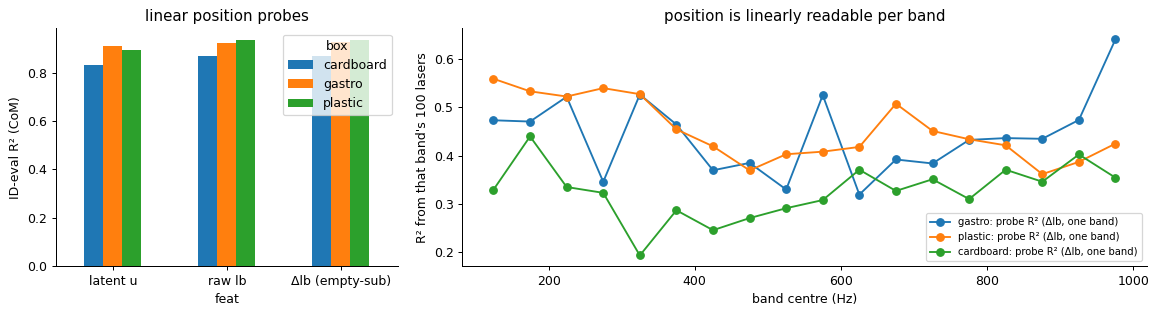

box              cardboard  gastro  plastic
feat                                       
latent u             0.830   0.911    0.896
raw lb               0.868   0.924    0.934
Δlb (empty-sub)      0.869   0.927    0.936
Spearman(band probe R², band occlusion ΔIoU) per box: [np.float64(-0.11), np.float64(0.54), np.float64(0.42)]


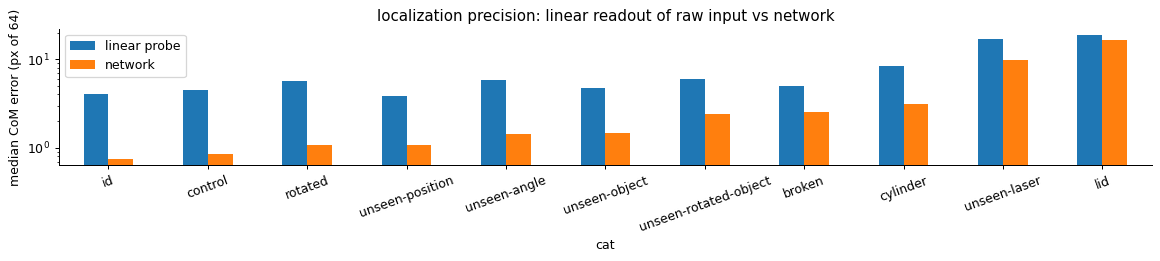

cat           broken  control  cylinder    id    lid  rotated  unseen-angle  unseen-laser  unseen-object  unseen-position  unseen-rotated-object
linear probe    4.98     4.44      8.46  4.04  18.90     5.75          5.82         16.84           4.78             3.90                   5.93
network         2.52     0.85      3.16  0.75  16.62     1.07          1.45          9.72           1.47             1.08                   2.43


In [6]:
from sklearn.linear_model import RidgeCV
LBE = {(b, s): LB[emp & (df.box == b).values & (df.spk == s).values].mean(0) for b, s in ref}
DLB = LB.copy(); DLB[ok] = LB[ok] - np.stack([LBE[b, s] for b, s in zip(df.box[ok], df.spk[ok])])
one = ok & (df.n_obj == 1).values
idev = (df.cat == "id").values
def probe(X, b, tr=TR, te=idev):
    a, t = tr & one & (df.box == b).values, te & one & (df.box == b).values
    mu, sd = X[a].mean(0), X[a].std(0) + 1e-6
    m = RidgeCV(alphas=np.logspace(-1, 5, 13)).fit((X[a] - mu) / sd, df.loc[a, ["r", "c"]].values)
    yp, yt = m.predict((X[t] - mu) / sd), df.loc[t, ["r", "c"]].values
    return 1 - ((yp - yt) ** 2).sum(0) / ((yt - yt.mean(0)) ** 2).sum(0)
rows = []
for b in ("gastro", "plastic", "cardboard"):
    for nm, X in (("raw lb", LB.reshape(N, -1)), ("Δlb (empty-sub)", DLB.reshape(N, -1)), ("latent u", U)): rows.append(dict(box=b, feat=nm, **dict(zip(("R2 row", "R2 col"), probe(X, b)))))
    for k in range(18): rows.append(dict(box=b, feat=f"band{k}", **dict(zip(("R2 row", "R2 col"), probe(DLB[:, :, k], b)))))
R3 = pd.DataFrame(rows); R3["R2"] = R3[["R2 row", "R2 col"]].mean(1)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[1, 2]))
pv = R3[~R3.feat.str.startswith("band")].pivot(index="feat", columns="box", values="R2"); pv.plot.bar(ax=ax[0], rot=0); ax[0].set(ylabel="ID-eval R² (CoM)", title="linear position probes")
for b, col in zip(("gastro", "plastic", "cardboard"), ("C0", "C1", "C2")):
    r = R3[(R3.box == b) & R3.feat.str.startswith("band")]; ax[1].plot(HZ, r.R2.clip(-.2), "o-", c=col, label=f"{b}: probe R² (Δlb, one band)")
ax[1].set(xlabel="band centre (Hz)", ylabel="R² from that band's 100 lasers", title="position is linearly readable per band"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show(); print(pv.round(3).to_string())
imp = np.array([[d(f"band{k}", ev & (sub.box == b).values) for k in range(18)] for b in ("gastro", "plastic", "cardboard")])
r2b = np.array([R3[(R3.box == b) & R3.feat.str.startswith("band")].R2.values for b in ("gastro", "plastic", "cardboard")])
print("Spearman(band probe R², band occlusion ΔIoU) per box:", [round(stats.spearmanr(a, c)[0], 2) for a, c in zip(r2b, imp)])
# precision: a linear readout of the raw levels vs the network, CoM error in px (64 px = box side), every eval category
rows = []
for b in ("gastro", "plastic", "cardboard"):
    a, t = TR & one & (df.box == b).values, EV & one & (df.box == b).values
    X = LB.reshape(N, -1); mu, sd = X[a].mean(0), X[a].std(0) + 1e-6
    yp = RidgeCV(alphas=np.logspace(-1, 5, 13)).fit((X[a] - mu) / sd, df.loc[a, ["r", "c"]].values).predict((X[t] - mu) / sd)
    e3 = df[t].copy(); e3["linear probe"] = np.hypot(*(yp - e3[["r", "c"]].values).T); e3["network"] = np.hypot(e3.r - e3.pr, e3.c - e3.pc); rows.append(e3)
e3 = pd.concat(rows).groupby("cat")[["linear probe", "network"]].median()
fig, ax = plt.subplots(figsize=(13, 3)); e3.sort_values("network").plot.bar(ax=ax, rot=20, logy=True); ax.set(ylabel="median CoM error (px of 64)", title="localization precision: linear readout of raw input vs network"); plt.tight_layout(); plt.show()
print(e3.round(2).T.to_string())

**Answer.** Position is not hidden. A ridge probe on the raw 100×18 per-laser band levels reaches CoM R² .87–.93 on ID eval, as high as the same probe on the latent (.83–.91). Subtracting the empty box adds nothing (.869 vs .868); a per-box linear model absorbs the baseline.
- **Every single band carries position** (R² .2–.64 from its 100 lasers alone), as expected when every mode shape samples the object location.
- **Probe R² agrees with band occlusion importance** in gastro and plastic (ρ .54 / .42) but not in cardboard (−.11).
- **The network's gain is precision, not detection.** Median CoM error is 0.75 px for the network vs 4.0 px for the linear readout on ID (5.4× better), 1.1 vs 3.9 px on unseen positions, and 1.5 vs 4.8 px on unseen objects. When the spatial code itself is broken (shifted lasers, lid), both fail (10–17 px).

## Q4 · What is the geometry of the latent?
Which nuisance and task factors are linearly present in `u` (probes: box, speaker, object classification accuracy; CoM R²), its PCA spectrum and participation ratio PR = (Σλ)²/Σλ², and — causally — the eval IoU when `u` is projected onto its top-k training PCs before decoding.

         input lb (PCA256)  latent u
box                  1.000     1.000
speaker              0.988     0.991
object               0.859     0.992 
chance: box .33, speaker .25


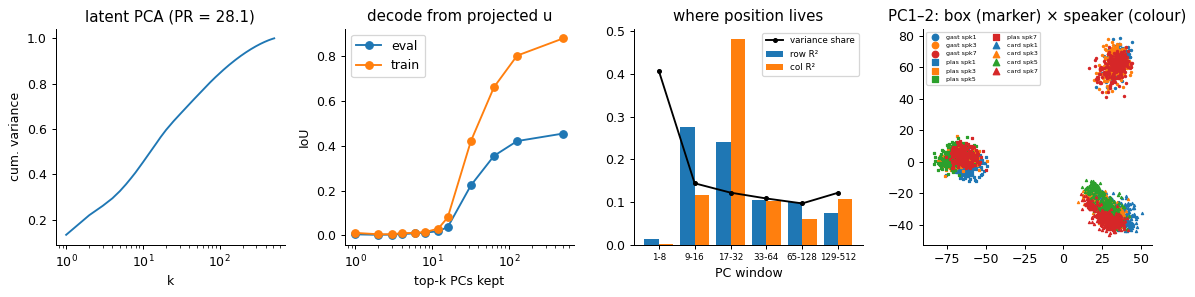

share of u variance explained by group means: {'box': np.float32(0.215), 'box×speaker': np.float32(0.382), 'box×object': np.float32(0.336), 'box×speaker×object': np.float32(0.538)}
position R² by PC window (row, col): {'1-8': [0.01, 0.0], '9-16': [0.28, 0.12], '17-32': [0.24, 0.48], '33-64': [0.1, 0.1], '65-128': [0.1, 0.06], '129-512': [0.08, 0.11]}
PR 28.1 | |ρ| of PC1..8 with (row, col): [[0.03, 0.06], [0.02, 0.01], [0.07, 0.03], [0.09, 0.04], [0.1, 0.05], [0.06, 0.02], [0.1, 0.0], [0.04, 0.01]]


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
def clf(X, y, tr=TR, te=EV):
    mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-6
    m = LogisticRegression(max_iter=300, C=0.1).fit((X[tr] - mu) / sd, y[tr]); return (m.predict((X[te] - mu) / sd) == y[te]).mean()
Xin = PCA(256, random_state=0).fit(LB.reshape(N, -1)[TR]).transform(LB.reshape(N, -1))
spk4 = df.spk.isin([1, 3, 5, 7]).values
fac = {}
for nm, X in (("input lb (PCA256)", Xin), ("latent u", U)):
    fac[nm] = dict(box=clf(X, df.box.values), speaker=clf(X, df.spk.values, TR & spk4, EV & spk4), object=clf(X, df.obj.values, TR, EV & (df.cat == "id").values))
print(pd.DataFrame(fac).round(3).to_string(), "\nchance: box .33, speaker .25")
pca = PCA(512).fit(U[TR]); lam = pca.explained_variance_; PR = lam.sum() ** 2 / (lam ** 2).sum()
Z = pca.transform(U)
ks = [1, 2, 3, 4, 6, 8, 12, 16, 32, 64, 128, 512]
fig, ax = plt.subplots(1, 4, figsize=(13, 3.4))
ax[0].semilogx(np.arange(1, 513), np.cumsum(lam) / lam.sum()); ax[0].set(xlabel="k", ylabel="cum. variance", title=f"latent PCA (PR = {PR:.1f})")
ax[1].semilogx(ks, [I[f"pc{k}"][ev].mean() for k in ks], "o-", label="eval"); ax[1].semilogx(ks, [I[f"pc{k}"][~ev].mean() for k in ks], "o-", label="train")
ax[1].set(xlabel="top-k PCs kept", ylabel="IoU", title="decode from projected u"); ax[1].legend()
W4 = [(0, 8), (8, 16), (16, 32), (32, 64), (64, 128), (128, 512)]; pr2 = []
for lo, hi in W4:  # position R² (ID eval) from one window of PCs only
    a, t = TR & one, EV & one & (df.cat == "id").values
    yp = RidgeCV(alphas=np.logspace(-2, 4, 7)).fit(Z[a, lo:hi], df.loc[a, ["r", "c"]].values).predict(Z[t, lo:hi]); yt = df.loc[t, ["r", "c"]].values
    pr2.append(1 - ((yp - yt) ** 2).sum(0) / ((yt - yt.mean(0)) ** 2).sum(0))
lab = [f"{lo + 1}-{hi}" for lo, hi in W4]; pr2 = np.array(pr2)
ax[2].bar(np.arange(6) - .2, pr2[:, 0], .4, label="row R²"); ax[2].bar(np.arange(6) + .2, pr2[:, 1], .4, label="col R²")
ax[2].plot(range(6), [pca.explained_variance_ratio_[lo:hi].sum() for lo, hi in W4], "k.-", label="variance share"); ax[2].set_xticks(range(6), lab, fontsize=7); ax[2].set(xlabel="PC window", title="where position lives"); ax[2].legend(fontsize=7)
m = TR & one; s = np.random.default_rng(0).choice(np.nonzero(m)[0], 3000, replace=False)
for b, mk in zip(("gastro", "plastic", "cardboard"), ("o", "s", "^")):
    for sp_ in (1, 3, 5, 7):
        mm = s[(df.box.values[s] == b) & (df.spk.values[s] == sp_)]; ax[3].scatter(Z[mm, 0], Z[mm, 1], s=3, marker=mk, c=f"C{sp_ // 2}", label=f"{b[:4]} spk{sp_}" if len(mm) else None)
ax[3].legend(markerscale=3, fontsize=5, ncol=2); ax[3].set_title("PC1–2: box (marker) × speaker (colour)")
plt.tight_layout(); plt.show()
Uc = U - U[TR].mean(0); tot = (Uc[TR] ** 2).sum()
print("share of u variance explained by group means:", {nm: round(((pd.DataFrame(Uc[TR]).groupby(k.values[TR]).transform("mean").values) ** 2).sum() / tot, 3)
      for nm, k in (("box", df.box), ("box×speaker", df.box + df.spk.astype(str)), ("box×object", df.box + df.obj), ("box×speaker×object", df.box + df.spk.astype(str) + df.obj))})
print("position R² by PC window (row, col):", dict(zip(lab, pr2.round(2).tolist())))
cor = [[abs(stats.spearmanr(Z[m, k], df.loc[m, f])[0]) for f in ("r", "c")] for k in range(8)]
print("PR", round(PR, 1), "| |ρ| of PC1..8 with (row, col):", np.round(cor, 2).tolist())

**Answer.** `u` is first a *context* code and only second a position code.
- **Context dominates.** Box, speaker and object are all linearly decodable at ≥ 99% (box 100%, speaker 99.1%, object 99.2%). Group means of box×speaker×object explain 54% of latent variance (box alone 21%).
- **Speaker is not removed.** It is as decodable from `u` as from the input (.991 vs .988). Object identity, by contrast, is *created* by the encoder (.86 → .99).
- **Position lives in mid-variance directions.** The top 8 PCs (41% of variance) carry zero position information (R² .01). Position lives in PCs 9–32 (R² up to .48), and decoding from the top 16 PCs gives IoU .04.
- **Memorization in the tail.** The decoder needs ~64–128 dims (eval .36 / .42 of .455). The last 384 low-variance PCs lift train IoU .80 → .88 but eval only .42 → .455. That is where the train-specific detail (memorization; train .89 vs eval .60) lives. Participation ratio 28.

## Q5 · Interpolation or lookup?
Two oracles that know the training set: copy the training mask whose **latent** is nearest (same box), and copy the training mask whose **input** (Δ`lb`, standardized) is nearest. If the model ≈ latent-NN, the decoder is a lookup table over training positions; if model > latent-NN, it interpolates. Also: IoU vs the distance from an eval object's CoM to the nearest training CoM of the same object in the same box (how far it must extrapolate).

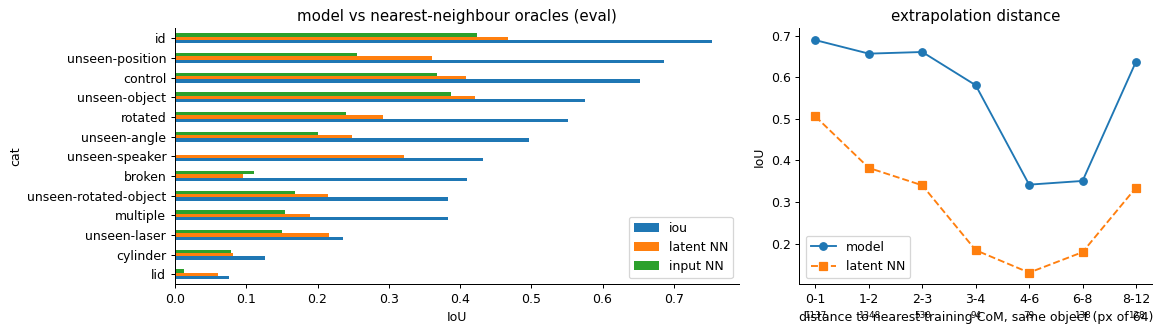

           iou       latent NN      
          mean  size      mean  size
dtrain                              
(0, 1]   0.689  1137     0.505  1137
(1, 2]   0.657  1348     0.382  1348
(2, 3]   0.661   530     0.340   530
(3, 4]   0.581    94     0.184    94
(4, 6]   0.342    79     0.130    79
(6, 8]   0.350   138     0.179   138
(8, 12]  0.637   128     0.334   128
                         iou  latent NN  input NN
cat                                              
broken                 0.410      0.095     0.111
control                0.652      0.409     0.368
cylinder               0.126      0.082     0.078
id                     0.754      0.468     0.424
lid                    0.076      0.061     0.012
multiple               0.383      0.189     0.154
rotated                0.552      0.292     0.240
unseen-angle           0.497      0.248     0.200
unseen-laser           0.236      0.216     0.150
unseen-object          0.575      0.421     0.387
unseen-position        0.686  

In [8]:
from sklearn.neighbors import NearestNeighbors
res = []
Xd = DLB.reshape(N, -1); Xd = np.nan_to_num(Xd)
for b in ("gastro", "plastic", "cardboard"):
    tb, eb = np.nonzero(TR & (df.box == b).values)[0], np.nonzero(EV & (df.box == b).values)[0]
    for nm, X in (("latent NN", U), ("input NN", Xd)):
        mu, sd = X[tb].mean(0), X[tb].std(0) + 1e-6
        j = tb[NearestNeighbors(n_neighbors=1).fit((X[tb] - mu) / sd).kneighbors((X[eb] - mu) / sd)[1][:, 0]]
        df.loc[eb, nm] = (Y[j] & Y[eb]).sum((1, 2)) / np.maximum((Y[j] | Y[eb]).sum((1, 2)), 1)
        if nm == "latent NN": df.loc[eb, "knn_u"] = NearestNeighbors(n_neighbors=10).fit((X[tb] - mu) / sd).kneighbors((X[eb] - mu) / sd)[0].mean(1)
        else: df.loc[eb, "knn_x"] = NearestNeighbors(n_neighbors=10).fit((X[tb] - mu) / sd).kneighbors((X[eb] - mu) / sd)[0].mean(1)
# distance to nearest training CoM of the same object in the same box
tr1 = df[TR & one]
df["dtrain"] = np.nan
for (b, o), g in df[EV & one].groupby(["box", "obj"]):
    t = tr1[(tr1.box == b) & (tr1.obj == o)]
    if len(t): df.loc[g.index, "dtrain"] = NearestNeighbors(n_neighbors=1).fit(t[["r", "c"]].values).kneighbors(g[["r", "c"]].values)[0][:, 0]
e = df[EV]
tab = e.groupby("cat")[["iou", "latent NN", "input NN"]].mean().round(3)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
tab.sort_values("iou").plot.barh(ax=ax[0]); ax[0].set(xlabel="IoU", title="model vs nearest-neighbour oracles (eval)")
seen = e[e.dtrain.notna()]; bins = [0, 1, 2, 3, 4, 6, 8, 12, 20, 40]
q = seen.groupby(pd.cut(seen.dtrain, bins))[["iou", "latent NN"]].agg(["mean", "size"])
x = [f"{i.left}-{i.right}" for i in q.index]
ax[1].plot(x, q[("iou", "mean")], "o-", label="model"); ax[1].plot(x, q[("latent NN", "mean")], "s--", label="latent NN")
for xi, n in zip(x, q[("iou", "size")]): ax[1].text(xi, .02, n, ha="center", fontsize=7)
ax[1].set(xlabel="distance to nearest training CoM, same object (px of 64)", ylabel="IoU", title="extrapolation distance"); ax[1].legend()
plt.tight_layout(); plt.show()
print(q.round(3).to_string()); print(tab.to_string()); print("all eval:", e[["iou", "latent NN", "input NN"]].mean().round(3).to_dict(), "| model > latentNN on", (e.iou > e["latent NN"]).mean().round(3))

**Answer.** The model interpolates.
- **It beats both oracles.** Model eval IoU is .596, vs .372 for copying the nearest training mask in latent space and .324 in input space. It beats the latent-NN oracle on 81% of samples.
- **Unseen positions:** .686 vs .360.
- **Interpolation radius.** IoU is flat (.66–.69) up to 3 px (~5% of the box) from the nearest training CoM of that object, then drops to ~.34 at 4–8 px. The NN oracle falls off much faster (.51 → .13).
- **Unseen speaker exposes the input space.** Input-space neighbours give **0.000**: a new speaker moves a scan so far that its nearest training inputs are not even the right scene. Latent neighbours recover .32. So the encoder *does* align speakers at the neighbourhood level, even though speaker stays linearly decodable (Q4).

## Q6 · What predicts per-sample success?
Gradient-boosted regression of per-sample eval IoU from properties of the data and of the model's state, evaluated with grouped 5-fold CV (groups = position, so no speaker-twin leakage). Permutation importance on held-out folds; marginal Spearman ρ alongside.

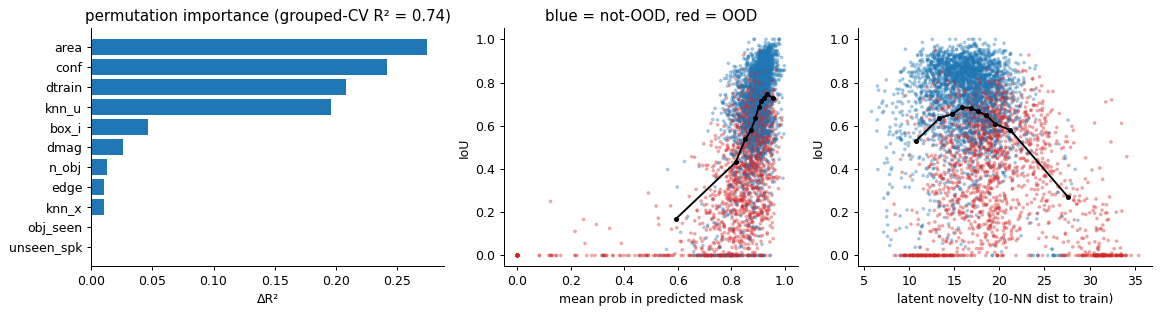

grouped-CV R² 0.739
             perm    rho
unseen_spk  0.000 -0.084
obj_seen    0.000  0.129
knn_x       0.010 -0.164
edge        0.010 -0.031
n_obj       0.013 -0.245
dmag        0.026  0.096
box_i       0.047 -0.169
knn_u       0.196 -0.223
dtrain      0.209 -0.183
conf        0.242  0.553
area        0.275  0.327


In [9]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
e = df[EV].copy()
e["box_i"] = e.box.map({"gastro": 0, "plastic": 1, "cardboard": 2}); e["unseen_spk"] = (e.spk == 4).astype(int)
e["obj_seen"] = e.obj.isin(INFO["objects"][:-1]).astype(int)
F6 = ["area", "n_obj", "edge", "dmag", "knn_u", "knn_x", "dtrain", "conf", "box_i", "unseen_spk", "obj_seen"]
X6, y6, grp = e[F6].values, e.iou.values, (e.exp + e.pos.astype(str)).values
pred, PI = np.zeros(len(e)), []
for a, t in GroupKFold(5).split(X6, y6, grp):
    m = HistGradientBoostingRegressor(max_iter=300, learning_rate=.05, random_state=0).fit(X6[a], y6[a]); pred[t] = m.predict(X6[t])
    PI.append(permutation_importance(m, X6[t], y6[t], n_repeats=5, random_state=0).importances_mean)
r2 = 1 - ((pred - y6) ** 2).sum() / ((y6 - y6.mean()) ** 2).sum()
imp6 = pd.DataFrame(dict(perm=np.mean(PI, 0), rho=[stats.spearmanr(e[f], e.iou, nan_policy="omit")[0] for f in F6]), index=F6).sort_values("perm")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
ax[0].barh(imp6.index, imp6.perm, color="C0"); ax[0].set(title=f"permutation importance (grouped-CV R² = {r2:.2f})", xlabel="ΔR²")
for a, f, lab in ((ax[1], "conf", "mean prob in predicted mask"), (ax[2], "knn_u", "latent novelty (10-NN dist to train)")):
    a.scatter(e[f], e.iou, s=4, alpha=.3, c=e.ood.map({True: "C3", False: "C0"})); a.set(xlabel=lab, ylabel="IoU")
    b = e.groupby(pd.qcut(e[f], 10, duplicates="drop")).agg(x=(f, "mean"), y=("iou", "mean")); a.plot(b.x, b.y, "k-o", ms=3)
ax[1].set_title("blue = not-OOD, red = OOD"); plt.tight_layout(); plt.show()
print("grouped-CV R²", round(r2, 3)); print(imp6.round(3).to_string())

**Answer.** Per-sample IoU is predictable (grouped-CV R² .74).
- **Strongest predictors:** true object area (perm. importance .28; small objects fail), the model's own mask confidence (.24, ρ .55), distance to the nearest training position of that object (.21), and latent novelty (.20).
- **Weak or no effect:**
  - Distance to the box edge has ~no effect (.01, ρ −.03), consistent with nb95 (edges are not weaker).
  - Raw-input novelty adds little (.01): what matters is how novel a sample looks *after* the encoder.
  - The unseen-speaker flag adds nothing once latent novelty is known.
  - Number of objects is weak (.013) but ρ −.25: multi-object scenes are worse, mostly through the second object.

## Q7 · Does the model know when it fails?
Failure = IoU < 0.3 on eval samples with an object. Scores: mask confidence (mean p inside the predicted mask), predicted area, latent novelty, input novelty, object-head max-softmax. AUROC per score, and the risk–coverage curve when abstaining on the least-confident samples. Also IoU vs threshold for ID and OOD: is .08 a calibration fix for OOD under-confidence?

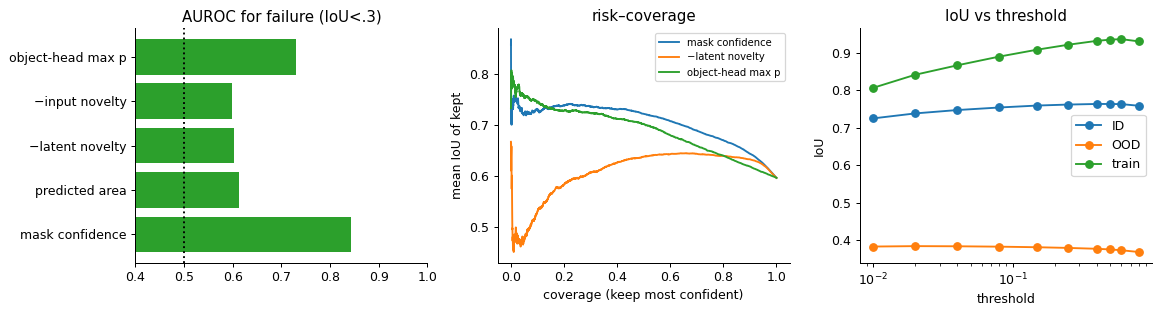

{'mask confidence': 0.843, 'predicted area': 0.613, '−latent novelty': 0.603, '−input novelty': 0.598, 'object-head max p': 0.73} | fail rate 0.167
ID IoU at [0.01, 0.02, 0.04, 0.08, 0.15, 0.25, 0.4, 0.5, 0.6, 0.8] [np.float64(0.725), np.float64(0.739), np.float64(0.748), np.float64(0.754), np.float64(0.76), np.float64(0.762), np.float64(0.764), np.float64(0.764), np.float64(0.764), np.float64(0.759)]
OOD IoU at [0.01, 0.02, 0.04, 0.08, 0.15, 0.25, 0.4, 0.5, 0.6, 0.8] [np.float64(0.383), np.float64(0.384), np.float64(0.384), np.float64(0.383), np.float64(0.381), np.float64(0.379), np.float64(0.377), np.float64(0.375), np.float64(0.373), np.float64(0.368)]
eval pixel prob histogram [0,.01,.08,.5,.92,1]: [0.9787 0.0026 0.0021 0.0019 0.0146]


In [10]:
from sklearn.metrics import roc_auc_score
e = df[EV].copy(); fail = (e.iou < .3).values
ol = torch.from_numpy(B["obj"][EV]).softmax(-1).numpy(); e["objp"] = ol.max(1)
S7 = {"mask confidence": e.conf, "predicted area": e.parea, "−latent novelty": -e.knn_u, "−input novelty": -e.knn_x, "object-head max p": e.objp}
auc = {k: roc_auc_score(fail, -v) for k, v in S7.items()}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].barh(list(auc), list(auc.values()), color="C2"); ax[0].axvline(.5, c="k", ls=":"); ax[0].set(xlim=(.4, 1), title="AUROC for failure (IoU<.3)")
for k in ("mask confidence", "−latent novelty", "object-head max p"):
    o = np.argsort(-S7[k].values); cov = np.arange(1, len(o) + 1) / len(o); ax[1].plot(cov, np.cumsum(e.iou.values[o]) / np.arange(1, len(o) + 1), label=k)
ax[1].set(xlabel="coverage (keep most confident)", ylabel="mean IoU of kept", title="risk–coverage"); ax[1].legend(fontsize=8)
th = [.01, .02, .04, .08, .15, .25, .4, .5, .6, .8]
for nm, m in (("ID", (df.cat == "id").values & EV), ("OOD", df.ood.values & EV), ("train", TR & (df.area > 0).values)):
    ax[2].plot(th, [np.mean(((P[m] > t) & Y[m]).sum((1, 2)) / np.maximum(((P[m] > t) | Y[m]).sum((1, 2)), 1)) for t in th], "o-", label=nm)
ax[2].set(xscale="log", xlabel="threshold", ylabel="IoU", title="IoU vs threshold"); ax[2].legend()
plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in auc.items()}, "| fail rate", fail.mean().round(3))
for nm, m in (("ID", (df.cat == "id").values & EV), ("OOD", df.ood.values & EV)): print(nm, "IoU at", th, [round(np.mean(((P[m] > t) & Y[m]).sum((1, 2)) / np.maximum(((P[m] > t) | Y[m]).sum((1, 2)), 1)), 3) for t in th])
hist = np.histogram(P[EV & (df.area > 0).values].ravel(), bins=[0, .01, .08, .5, .92, 1.01])[0]; print("eval pixel prob histogram [0,.01,.08,.5,.92,1]:", (hist / hist.sum()).round(4))

**Answer.** Partly. **Mask confidence** detects failures (IoU < .3, 16.7% of eval) with AUROC .84, the object head's max-p with .73, and latent / input novelty only with ~.60. Abstaining on the least-confident 20% lifts mean IoU from .596 to .670 (risk–coverage curve).
- **The masks are almost binary.** 97.9% of eval pixels are < .01, 1.5% are > .92, and only 0.7% are in between. The model is decisive even when it is wrong, so its confidence lives in *how much* it paints, not in soft edges.
- **The threshold therefore barely matters.** ID IoU goes .725 @ .01 → .754 @ .08 → .764 @ .5; OOD is flat at .38 across .01–.25. The .08 goal threshold is not compensating for OOD under-confidence; ID would gain +.01 at .4–.5.

## Q8 · How invariant is it to the speaker (excitation) and to noise?
The measured spectrum is X(f) = S(f)·H_box(f; object)·sensor(f): the speaker response S(f) multiplies everything and is the main nuisance. (a) Variance decomposition at positions recorded with all four training speakers: fraction of variance between positions vs within position (across speakers), in the input and in `u`. (b) Test-time random smooth speaker responses (log-gain sd, knot spacing 20 Hz; 5 Hz = ragged, 80 Hz = smooth tilt) and additive noise at a given SNR.

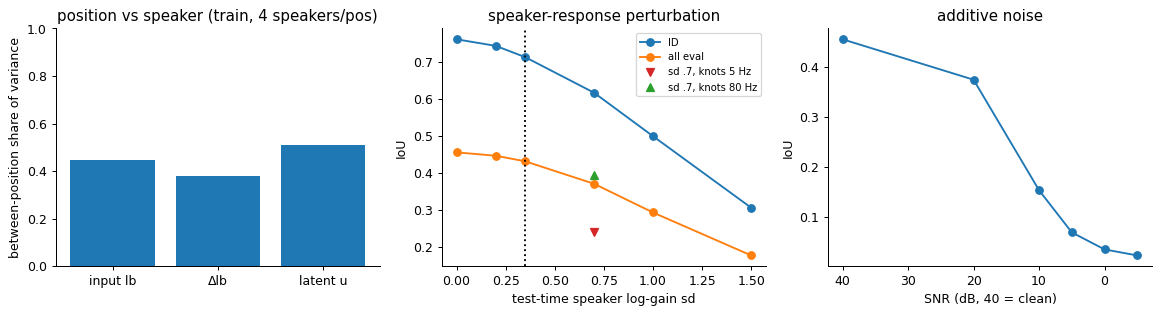

{'input lb': np.float32(0.447), 'Δlb': np.float32(0.378), 'latent u': np.float32(0.512)} {'clean': np.float32(0.455), 'sg0.35': np.float32(0.43), 'sg0.7': np.float32(0.37), 'sgHz5.0': np.float32(0.239), 'sgHz80.0': np.float32(0.393), 'snr10': np.float32(0.154), 'snr0': np.float32(0.036), 'gain_global': np.float32(0.455)}
gastro    unseen spk IoU 0.187 vs baseline 0.658 | latent novelty 28.0 vs 15.7 | input novelty 59.3 vs 19.7
plastic   unseen spk IoU 0.650 vs baseline 0.741 | latent novelty 23.2 vs 18.5 | input novelty 44.4 vs 25.7
cardboard unseen spk IoU 0.414 vs baseline 0.666 | latent novelty 24.6 vs 17.5 | input novelty 62.2 vs 24.5


In [11]:
def icc(X, m):
    g = df[m].groupby(["exp", "pos"]).spk.transform("nunique") == 4; idx = np.nonzero(m)[0][g.values]
    keys = (df.exp + df.pos.astype(str)).values[idx]; Xs = (X[idx] - X[idx].mean(0)) / (X[idx].std(0) + 1e-6)
    mu = pd.DataFrame(Xs).groupby(keys).transform("mean").values
    return ((mu - Xs.mean(0)) ** 2).sum() / ((Xs - Xs.mean(0)) ** 2).sum()
m8 = TR & (df.n_obj == 1).values
V8 = {nm: icc(X, m8) for nm, X in (("input lb", LB.reshape(N, -1)), ("Δlb", np.nan_to_num(DLB.reshape(N, -1))), ("latent u", U))}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].bar(list(V8), list(V8.values()), color="C0"); ax[0].set(ylim=(0, 1), ylabel="between-position share of variance", title="position vs speaker (train, 4 speakers/pos)")
sg = [0, .2, .35, .7, 1.0, 1.5]
for nm, m in (("ID", (sub.cat == "id").values), ("all eval", ev)): ax[1].plot(sg, [I["clean"][m].mean()] + [I[f"sg{s}"][m].mean() for s in sg[1:]], "o-", label=nm)
ax[1].plot([.7], [I["sgHz5.0"][ev].mean()], "v", c="C3", label="sd .7, knots 5 Hz"); ax[1].plot([.7], [I["sgHz80.0"][ev].mean()], "^", c="C2", label="sd .7, knots 80 Hz")
ax[1].axvline(.35, c="k", ls=":"); ax[1].set(xlabel="test-time speaker log-gain sd", ylabel="IoU", title="speaker-response perturbation"); ax[1].legend(fontsize=8)
snr = [40, 20, 10, 5, 0, -5]
ax[2].plot(snr, [I["clean"][ev].mean()] + [I[f"snr{s}"][ev].mean() for s in snr[1:]], "o-"); ax[2].invert_xaxis(); ax[2].set(xlabel="SNR (dB, 40 = clean)", ylabel="IoU", title="additive noise")
plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in V8.items()}, {k: round(I[k][ev].mean(), 3) for k in ["clean", "sg0.35", "sg0.7", "sgHz5.0", "sgHz80.0", "snr10", "snr0", "gain_global"]})
# unseen speaker: how far is speaker 4 from the training manifold, vs the same positions with training speakers
for b, nm in (("gastro", "cube"), ("plastic", "cube"), ("cardboard", "vase")):
    u4, ub = df[df.split == f"eval/{b}/{nm}-unseen-speaker-unseen"], df[df.split == f"eval/{b}/{nm}-unseen-speaker-baseline"]
    print(f"{b:9s} unseen spk IoU {u4.iou.mean():.3f} vs baseline {ub.iou.mean():.3f} | latent novelty {u4.knn_u.mean():.1f} vs {ub.knn_u.mean():.1f} | input novelty {u4.knn_x.mean():.1f} vs {ub.knn_x.mean():.1f}")

**Answer.** It is only partly speaker-invariant.
- **Variance share.** At positions recorded with all 4 training speakers, between-position variance is 45% of the input and only 51% of the latent: the encoder raises the position share by just 6 pp, and half the latent variance is still speaker.
- **Test-time speaker response.** At the training level (log-gain sd .35) IoU drops .455 → .430; at sd .7 to .37, at sd 1.0 to .29. *Ragged* responses hurt far more than smooth ones at the same sd: knots every 5 Hz give .24, every 80 Hz give .39. The model tolerates spectral tilt but not ripple on the scale of modal linewidths, which is exactly where it reads the signal (Q1).
- **Noise.** It is very noise-sensitive: 20 dB SNR → .37, 10 dB → .15. The object information sits only ~10–20 dB above the floor, consistent with signal ≈ 1.3–2.8× the repeat noise (Q2).
- **Unseen speaker 4.** It moves the input 2.4–3× further from the training set, but the latent only 1.3–1.8× further. Gastro fails worst (IoU .19 vs .66 baseline) and has the largest input (3.0×) and latent (1.8×) shift. Plastic barely moves (1.25×) and keeps .65.

## Q9 · How does the laser array encode space?
Per-laser occlusion maps (10×10), redundancy (random k of 100 lasers dropped), grid shift (bilinear resample of the laser field by U(−s, s) cells), mirroring the grid (does the predicted blob mirror?), and the real shifted-laser captures.

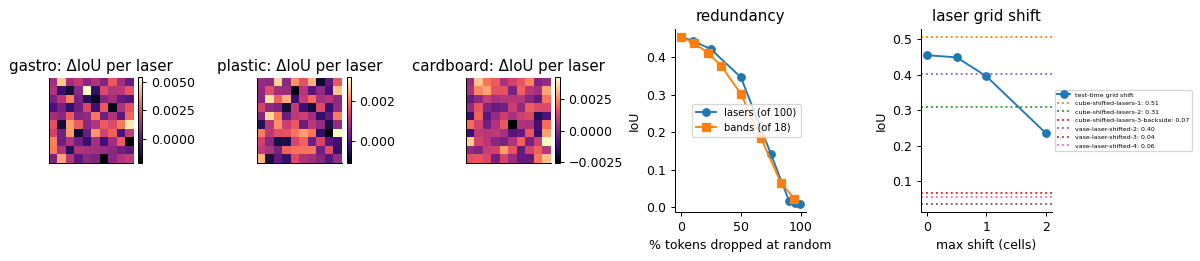

flip_lr IoU 0.066 | corr(pred row, clean row) 0.25 | corr(pred col, clean col) 0.11
flip_ud IoU 0.075 | corr(pred row, clean row) 0.23 | corr(pred col, clean col) 0.22
ρ(importance-weighted laser row/col, object row/col): {'lrow~r': np.float64(0.03), 'lrow~c': np.float64(-0.01), 'lcol~r': np.float64(0.01), 'lcol~c': np.float64(0.07)} n = 1511
single laser max mean ΔIoU 0.0028 | rows [np.float32(0.019), np.float32(0.014), np.float32(0.011), np.float32(0.013), np.float32(0.01), np.float32(0.012), np.float32(0.014), np.float32(0.013), np.float32(0.012), np.float32(0.009)] | cols [np.float32(0.012), np.float32(0.015), np.float32(0.014), np.float32(0.009), np.float32(0.013), np.float32(0.012), np.float32(0.013), np.float32(0.011), np.float32(0.008), np.float32(0.019)]


In [12]:
L = np.stack([I["clean"] - I[f"laser{l}"] for l in range(100)], 1)            # (n_sub,100) ΔIoU per laser
fig, ax = plt.subplots(1, 5, figsize=(13, 3.0), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.4, 1.4]))
for a, b in zip(ax[:3], ("gastro", "plastic", "cardboard")):
    h = a.imshow(L[ev & (sub.box == b).values].mean(0).reshape(10, 10), cmap="magma"); a.set_title(f"{b}: ΔIoU per laser"); a.set_xticks([]); a.set_yticks([]); plt.colorbar(h, ax=a, fraction=.046)
ks = [0, 10, 25, 50, 75, 90, 95, 99]
ax[3].plot(ks, [I["clean"][ev].mean()] + [I[f"rl{k}"][ev].mean() for k in ks[1:]], "o-", label="lasers (of 100)")
kb = [0, 2, 4, 6, 9, 12, 15, 17]; ax[3].plot(np.array(kb) / 18 * 100, [I["clean"][ev].mean()] + [I[f"rb{k}"][ev].mean() for k in kb[1:]], "s-", label="bands (of 18)")
ax[3].set(xlabel="% tokens dropped at random", ylabel="IoU", title="redundancy"); ax[3].legend(fontsize=8)
js = [0, 0.5, 1.0, 2.0]; ax[4].plot(js, [I["clean"][ev].mean()] + [I[f"jit{s}"][ev].mean() for s in js[1:]], "o-", label="test-time grid shift")
sl = df[df.name.str.contains("shift") & EV].groupby("name").iou.mean();
for i, (k, v) in enumerate(sl.items()): ax[4].axhline(v, ls=":", c=f"C{i + 1}", label=f"{k}: {v:.2f}")
ax[4].set(xlabel="max shift (cells)", ylabel="IoU", title="laser grid shift"); ax[4].legend(fontsize=5, loc="center left", bbox_to_anchor=(1, .5))
plt.tight_layout(); plt.show()
# mirror test: flip the grid's columns / rows -> where does the blob go?
Cc, Cf, Cu = A["com"][names.index("clean")], A["com"][names.index("flip_lr")], A["com"][names.index("flip_ud")]
for nm, Cx in (("flip_lr", Cf), ("flip_ud", Cu)):
    print(nm, "IoU", I[nm][ev].mean().round(3), "| corr(pred row, clean row)", np.corrcoef(Cx[ev, 0], Cc[ev, 0])[0, 1].round(2), "| corr(pred col, clean col)", np.corrcoef(Cx[ev, 1], Cc[ev, 1])[0, 1].round(2))
# does the important laser sit near the object? importance-weighted laser (row, col) vs object CoM
w = L.clip(0); lr, lc = np.divmod(np.arange(100), 10); m = ev & (w.sum(1) > .02)
wr, wc = (w * lr).sum(1)[m] / w.sum(1)[m], (w * lc).sum(1)[m] / w.sum(1)[m]
print("ρ(importance-weighted laser row/col, object row/col):", {f"{a}~{b}": round(stats.spearmanr(x, sub[b].values[m])[0], 2) for a, x in (("lrow", wr), ("lcol", wc)) for b in ("r", "c")}, "n =", m.sum())
print("single laser max mean ΔIoU", L[ev].mean(0).max().round(4), "| rows", [round(d(f'lrow{k}'), 3) for k in range(10)], "| cols", [round(d(f'lcol{k}'), 3) for k in range(10)])

**Answer.** The array works as a *fixed-sensor fingerprint*, not as an image of the floor.
- **No single laser matters.** The best single laser is worth ≤ .003 IoU (noise level), and a whole row or column .008–.019.
- **Graceful degradation.** Random dropout of 25% / 50% / 75% of lasers gives .42 / .35 / .14 (clean .455); bands behave the same. Training-time token dropout buys this.
- **Laser placement must be exact.** A ±.5-cell grid shift (the training augmentation) is free, ±1 cell costs −.06 and ±2 cells −.22. The real shifted-laser captures score .51 / .31 / .07 (plastic) and .40 / .04 / .06 (cardboard).
- **No mirror equivariance.** Mirroring the grid left-right or up-down does *not* mirror the prediction: IoU .07, and the predicted CoM is barely correlated with the clean one (ρ .1–.25).
- **Non-local coding.** The importance-weighted laser position is uncorrelated with the object position (|ρ| ≤ .07): no "nearest laser" sees the object. All of this fits modal physics. The wall lasers sample global box modes that an object anywhere on the floor perturbs. Position is a pattern over all lasers, read through per-laser weights (rope position + one flatten-readout slot per laser). It is not a local dip that could translate.

## Q10 · What happens off-distribution?
Per eval split: mean latent novelty vs mean IoU (does distance from the training manifold explain split-level failure?), which training class the object head assigns to unseen objects, and predicted vs true mask area per object (does the model paint a *size* or a *class template*?).

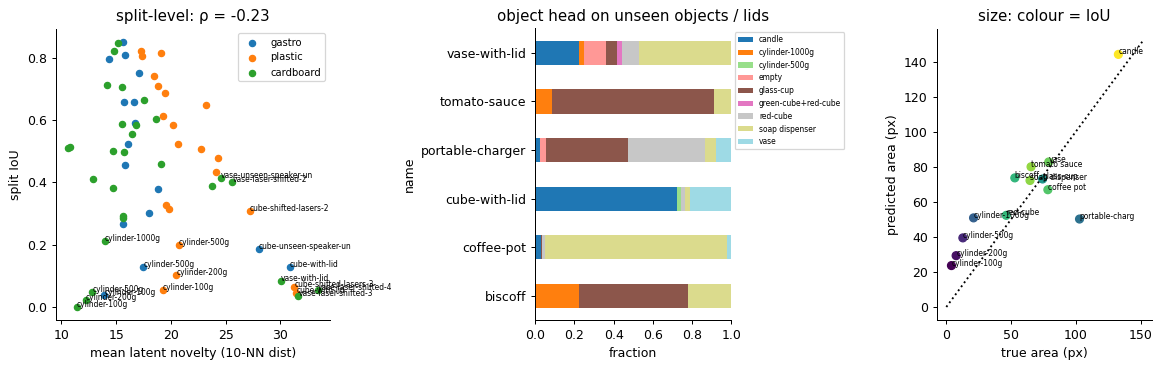

split-level ρ(novelty, IoU) -0.233 | log-log slope pred vs true area 0.39
head              candle  cylinder-1000g  cylinder-500g  empty  glass-cup  green-cube+red-cube  red-cube  soap dispenser  vase
name                                                                                                                          
biscoff             0.00            0.22           0.00   0.00       0.56                 0.00      0.00            0.22  0.00
coffee-pot          0.03            0.00           0.00   0.00       0.00                 0.00      0.02            0.93  0.02
cube-with-lid       0.72            0.00           0.02   0.00       0.00                 0.00      0.02            0.02  0.21
portable-charger    0.03            0.00           0.00   0.03       0.42                 0.00      0.39            0.05  0.08
tomato-sauce        0.00            0.09           0.00   0.00       0.83                 0.00      0.00            0.09  0.00
vase-with-lid       0.22            0

In [13]:
e = df[EV].copy(); e["head"] = np.array([o or "empty" for o in INFO["objects"][:-1]])[B["obj"][EV].argmax(1)]
sp = e.groupby(["box", "name"]).agg(iou=("iou", "mean"), nov=("knn_u", "mean"), xnov=("knn_x", "mean"), ood=("ood", "first"), area=("area", "mean"), parea=("parea", "mean")).reset_index()
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1.4, 1, 1.1]))
for (b, col) in zip(("gastro", "plastic", "cardboard"), ("C0", "C1", "C2")):
    s = sp[sp.box == b]; ax[0].scatter(s.nov, s.iou, c=col, s=25, label=b)
    for _, r in s[(s.iou < .25) | (s.nov > sp.nov.quantile(.85))].iterrows(): ax[0].annotate(r["name"][:22], (r.nov, r.iou), fontsize=6)
ax[0].set(xlabel="mean latent novelty (10-NN dist)", ylabel="split IoU", title=f"split-level: ρ = {stats.spearmanr(sp.nov, sp.iou)[0]:.2f}"); ax[0].legend(fontsize=8)
un = e[e.name.isin(["coffee-pot", "portable-charger", "biscoff", "tomato-sauce", "cube-with-lid", "vase-with-lid"])]
ct = pd.crosstab(un.name, un["head"], normalize="index"); ct.plot.barh(stacked=True, ax=ax[1], legend=False, colormap="tab20"); ax[1].set(title="object head on unseen objects / lids", xlabel="fraction")
ax[1].legend(fontsize=6, bbox_to_anchor=(1, 1))
o = e[e.n_obj == 1].groupby("obj").agg(a=("area", "mean"), pa=("parea", "mean"), iou=("iou", "mean"))
ax[2].scatter(o.a, o.pa, c=o.iou, cmap="viridis", s=40); [ax[2].annotate(k[:14], (r.a, r.pa), fontsize=6) for k, r in o.iterrows()]
lim = [0, max(o.a.max(), o.pa.max()) * 1.05]; ax[2].plot(lim, lim, "k:"); ax[2].set(xlabel="true area (px)", ylabel="predicted area (px)", title="size: colour = IoU")
plt.tight_layout(); plt.show()
print("split-level ρ(novelty, IoU)", round(stats.spearmanr(sp.nov, sp.iou)[0], 3), "| log-log slope pred vs true area", round(np.polyfit(np.log(o.a), np.log(o.pa), 1)[0], 2))
print(ct.round(2).to_string()); print(o.round(2).sort_values("a").to_string())
# lid: the whole box spectrum moves
for b, a_, b_ in (("gastro", "cube-with-lid", "cube-without-lid"), ("plastic", "cube-with-lid", "cube-without-lid"), ("cardboard", "vase-with-lid", "vase-without-lid")):
    w, wo = df[df.split == f"eval/{b}/{a_}"], df[df.split == f"eval/{b}/{b_}"]
    print(f"{b:9s} lid IoU {w.iou.mean():.3f} vs no-lid {wo.iou.mean():.3f} | latent novelty {w.knn_u.mean():.1f} vs {wo.knn_u.mean():.1f} | rms Δspec vs empty {w.dmag.mean():.3f} vs {wo.dmag.mean():.3f}")

**Answer.** Off-distribution failures come in two kinds, so latent novelty explains split-level IoU only weakly (ρ = −.23).
- **(i) Low-novelty misses.** The cylinders sit at the *lowest* novelty (11–17), yet score IoU ≤ .3: their perturbation is too small to move the scan away from the training distribution, so the model treats them as familiar and mis-sizes them (Q2).
- **(ii) High-novelty global shifts.**
  - The lid changes the box's own resonances: its rms change vs the empty box is 3.4–3.9× an object's (.79 vs .22), latent novelty ~31 vs 16–24, and IoU .04–.13.
  - Shifted lasers and unseen speaker 4 in gastro fall in the same high-novelty group.
- **Unseen objects snap to a training class.**
  - Coffee pot → soap dispenser (93%), IoU .62.
  - Tomato sauce → glass cup (83%), IoU .71.
  - Biscoff → glass cup (56%).
  - Portable charger → glass cup / red cube.
  - The lid → candle (72%).
- **Painted size shrinks toward a prior.** Log-log slope of predicted vs true area is .39: small objects are over-painted (4 px cylinder → 24 px), the 103 px charger is under-painted (50 px), and objects near the class sizes (50–130 px) are right. The model localizes from the vibration and draws a *size/shape prior* inherited from the nearest training class.

## Summary

| # | question | short answer |
|---|---|---|
| 1 | what is read | the spatial pattern across lasers (wall-mean → −.38), sharp modal lines (smoothing → −.18), both axes; no band essential (≤ .02) |
| 2 | physical signature | object Δ only 1.3–2.8× repeat noise and dominated by drift; IoU rises with cylinder size; unseen cylinders are found (≤1.3 px) but painted 3–15× too big |
| 3 | where position is | linearly in the raw levels (R² .87–.93, every band); the network gives 5× precision (0.75 vs 4.0 px) |
| 4 | latent geometry | context code first (box/speaker/object ≥ 99%), position in PCs 9–32; low-variance tail = memorization |
| 5 | interpolation? | yes: .60 vs NN oracles .37/.32; flat to 3 px from training positions |
| 6 | success predictors | object area, confidence, distance to training, latent novelty (R² .74); edges irrelevant |
| 7 | knows when wrong | mask confidence AUROC .84; masks ~binary, threshold irrelevant |
| 8 | speaker / noise | half the latent is still speaker; ripple ≫ tilt; 10 dB SNR → .15 |
| 9 | laser array | non-local fingerprint, no single laser matters, no equivariance; ±1 cell shift −.06 |
| 10 | off-distribution | two failure modes (too small = low novelty, global box change = high novelty); unseen objects snap to a class size prior |

**Why runs succeed or fail, in one line each.**
- **Success:** a mid-to-large object (≥ 40 px) within ~3 px of training positions, in a box/speaker state the encoder has seen. The model then interpolates a precise (< 1 px) location from a non-local modal fingerprint and pastes a class-size blob.
- **Failure:** the object is small or light (signal under the drift floor), the box state changes globally (lid, speaker 4 in gastro, shifted lasers), or the object's size is far from any training class.

Caveats: single seed / single checkpoint (ep300). The ablation subset is ≤ 30 samples per eval split (per-split numbers ±.05). Occlusion uses the model's own token masks (trained with dropout on 10% of samples, so a drop is in-distribution). Cylinder mass and size are confounded. The mirror / axis-duplication probes are OOD inputs, so they bound reliance but do not give clean attribution.